# 01 — Data Cleaning & Exploratory Data Analysis

**Project:** AI-Powered Energy Consumption Forecasting & Anomaly Detection System
**Dataset:** REWDP (Residential Energy and Weather Data Pakistan) — Karachi House 38
**Goal:** Load the raw minute-level smart-meter data, fix the data-quality problems found during inspection, and understand the consumption patterns before any modelling.

**Notebook order:** 00 (raw exploration) → **01** → 02 → 03 → 04 → 05 → 06 → 07.
Notebooks 02, 03, 04 and 06 read files saved by the previous notebooks. Each of them has two folder variables at the top: `IN_DIR` (where the earlier files are) and `WORK_DIR` (where this notebook saves). On Kaggle, add the previous notebook's output as an input to the next notebook, set `IN_DIR` to that input path, and keep `WORK_DIR` as the writable working folder.

**What we fix here:**
1. Some timestamps repeat many times in a row (the meter buffered readings and dumped them together after a connection drop).
2. During those gaps `Usage (kW)` reads a flat `0` for ~59 minutes. That is sensor downtime, not real zero usage.
3. After fixing both, we resample to hourly values and keep a flag (`observed`) that says which hours are real measurements and which were filled.

## 1.1 Load the raw data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_ROOT = "/kaggle/input/datasets/azizullahasad/rewp-ai-project/rewdp_dataset_small/rewdp_dataset"
WEATHER_ROOT = "/kaggle/input/weather-dataset/weather_dataset"
WORK_DIR = "."   # folder where notebooks 01-06 save/read their files

df = pd.read_csv(f"{DATA_ROOT}/Karachi/karachi_House38.csv")
if "Usage..kW." in df.columns:
    df = df.rename(columns={"Usage..kW.": "Usage (kW)"})

print(df.shape)
print(df.columns.tolist())
df.head()

(526463, 7)
['datetime', 'Usage (kW)', 'Washing Machine (kW)', 'BR_1_AC (kW)', 'BR_2_AC (kW)', 'Fridge + Water Pump (kW)', 'Kitchen (kW)']


,datetime,Usage (kW),Washing Machine (kW),BR_1_AC (kW),BR_2_AC (kW),Fridge + Water Pump (kW),Kitchen (kW)
0,2023-09-02 12:07:00,1.227850,0.007483,0.009967,0.010850,0.426783,0.006817
1,2023-09-02 12:08:00,0.574583,0.003550,0.004517,0.004883,0.215233,0.003400
2,2023-09-02 12:09:00,0.418283,0.003050,0.003850,0.004300,0.124283,0.001933
3,2023-09-02 12:10:00,0.408000,0.002700,0.003683,0.004333,0.114417,0.001917
4,2023-09-02 12:11:00,0.409117,0.002450,0.004033,0.004567,0.114067,0.001500


## 1.2 Problem 1 — Duplicate timestamps

In the raw file the same `datetime` can repeat dozens of times in a row. This happens when the meter loses its connection and, on reconnecting, dumps all buffered minute-readings under one timestamp.

**Fix:** find every run of identical consecutive timestamps and re-stamp the rows one second apart (0 s, 1 s, 2 s, ...). Nothing is dropped, and every timestamp becomes unique and in order.

How the code works:
- `times != times.shift()` is `True` whenever the timestamp changes, so `.cumsum()` gives every run its own number (`run_id`).
- `groupby(run_id).cumcount()` counts 0, 1, 2, ... inside each run.
- We add that count as seconds to the timestamp.

In [2]:
times = pd.to_datetime(df["datetime"], format="mixed")

run_id = (times != times.shift()).cumsum()               # one number per run of equal timestamps
position_in_run = df.groupby(run_id).cumcount()          # 0, 1, 2, ... inside each run

df["datetime"] = times + pd.to_timedelta(position_in_run, unit="s")
df = df.set_index("datetime").sort_index()
df = df[~df.index.duplicated(keep="first")]               # safety net, should drop nothing

print("Duplicate datetime:", df.index.duplicated().sum())
print("Sorted:", df.index.is_monotonic_increasing)
print("Missing datetime:", df.index.isna().sum())

Duplicate datetime: 0
Sorted: True
Missing datetime: 0


## 1.3 Problem 2 — Fake zero streaks (sensor downtime)

Exactly where the duplicates occur, `Usage (kW)` is a flat `0` for ~59 minutes. That is the sensor being offline, **not** real zero consumption. If we keep these zeros they would show up as false "sudden drop to zero" anomalies and would distort the hourly averages.

**Fix:** find every run of 10 or more zero-minutes in a row and mark the **whole run** as missing (`NaN`).

In [3]:
df = df.apply(pd.to_numeric, errors="coerce")

is_zero = df["Usage (kW)"] == 0
zero_run = (is_zero != is_zero.shift()).cumsum()           # number each run of zeros / non-zeros
run_len = is_zero.groupby(zero_run).transform("size")      # length of the run each row belongs to

downtime = is_zero & (run_len >= 10)
print("Rows marked as sensor downtime:", int(downtime.sum()))

df.loc[downtime, :] = np.nan

Rows marked as sensor downtime: 22945


## 1.4 Resample to hourly

Minute data (~526,000 rows) is more detail than forecasting needs. We take the **hourly mean** and then:

- An hour with less than half an hour of data is set to missing.
- `observed` remembers which hours are **real measurements**.
- Gaps of up to **3 hours** are filled by time interpolation (so the lag features stay usable). Longer gaps stay missing — we do not invent days of data.
- Later, only `observed` hours are used as forecasting targets, so the model is never trained or scored on filled values.

In [4]:
usage_cols = [c for c in ["Usage (kW)", "Washing Machine (kW)", "BR_1_AC (kW)", "BR_2_AC (kW)",
                          "Fridge + Water Pump (kW)", "Kitchen (kW)"] if c in df.columns]

hourly = df[usage_cols].resample("h").mean()

n_rows = df["Usage (kW)"].resample("h").count()           # how many valid minute-rows in each hour
hourly.loc[n_rows < 30, :] = np.nan                       # less than half an hour of data -> missing hour

hourly["observed"] = hourly["Usage (kW)"].notna()         # True = real measured hour

hourly[usage_cols] = hourly[usage_cols].interpolate(method="time", limit=3, limit_area="inside")

print("Hours in table      :", len(hourly))
print("Real (observed)     :", int(hourly["observed"].sum()), f"({100 * hourly['observed'].mean():.2f} %)")
print("Still missing (long gaps):", int(hourly["Usage (kW)"].isna().sum()))
print("Period:", hourly.index.min(), "->", hourly.index.max())
hourly.head()

Hours in table      : 8393
Real (observed)     : 8392 (99.99 %)
Still missing (long gaps): 0
Period: 2023-09-02 12:00:00 -> 2024-08-17 04:00:00


,Usage (kW),Washing Machine (kW),BR_1_AC (kW),BR_2_AC (kW),Fridge + Water Pump (kW),Kitchen (kW),observed
datetime,,,,,,,
2023-09-02 12:00:00,0.526868,0.003235,0.004568,0.005349,0.153806,0.002909,True
2023-09-02 13:00:00,1.298505,0.004410,0.004978,0.004553,0.239058,0.002941,True
2023-09-02 14:00:00,1.857305,0.004286,0.004638,0.002990,0.205566,0.036126,True
2023-09-02 15:00:00,1.619104,0.002441,0.002962,0.002348,0.254719,0.001775,True
2023-09-02 16:00:00,1.593942,0.003102,0.002518,0.004691,0.225510,0.003807,True


## 1.5 Exploratory visualisation

Three views: the full-period trend (seasonality), the average pattern by hour of day (daily peaks) and the average usage per month.

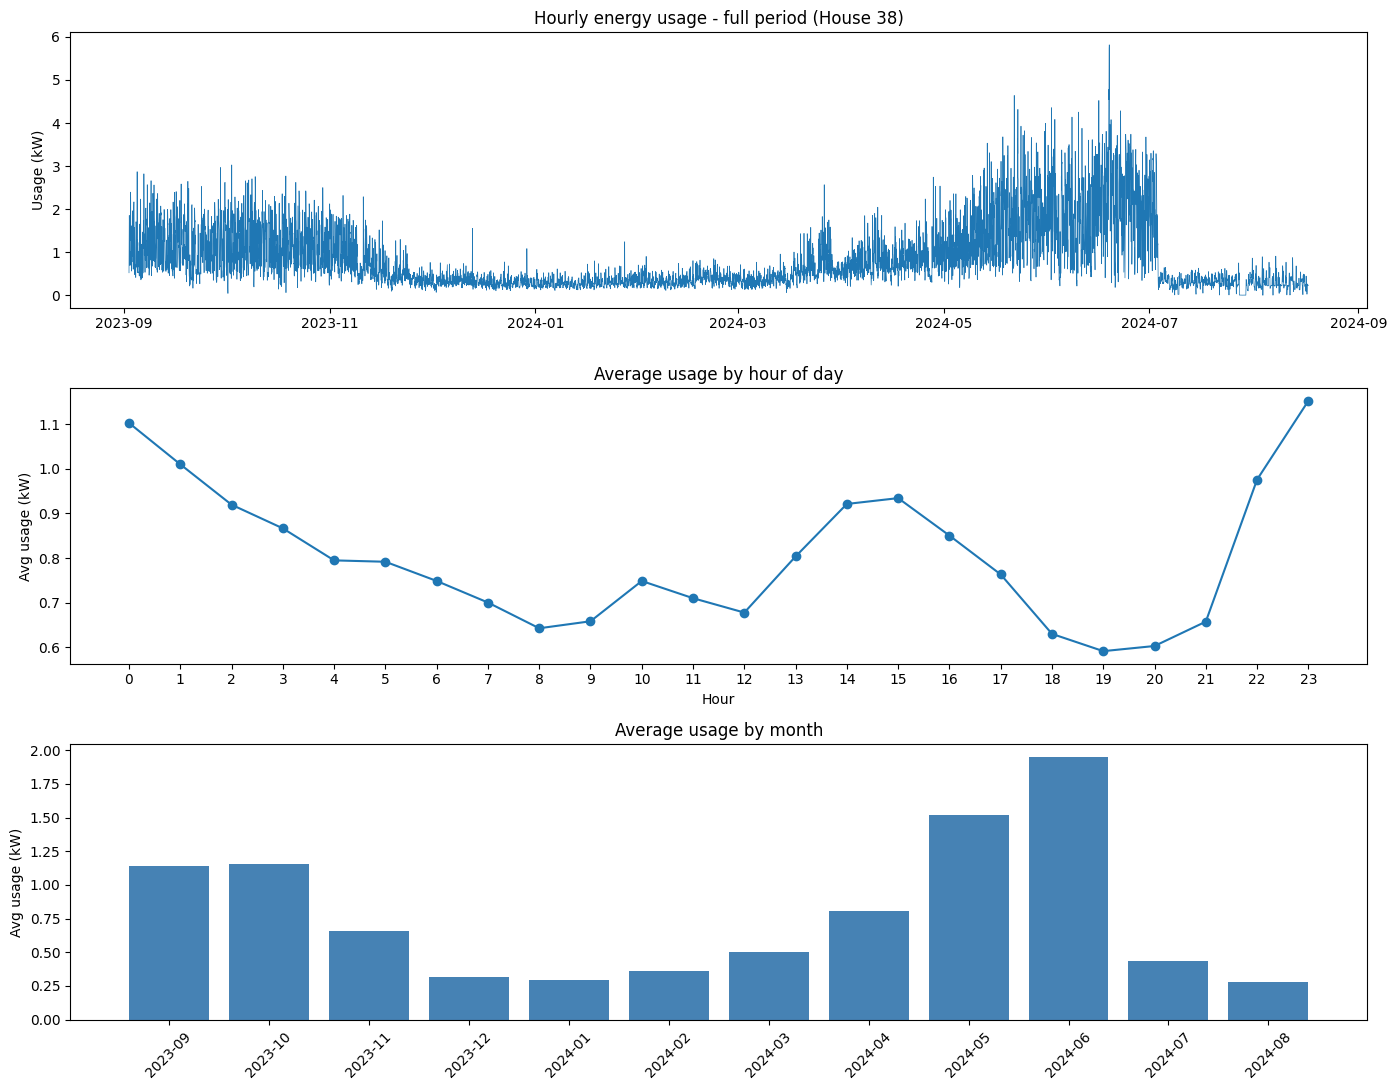

In [5]:
usage = hourly["Usage (kW)"]

fig, axes = plt.subplots(3, 1, figsize=(14, 11))

axes[0].plot(usage.index, usage.values, linewidth=0.5)
axes[0].set_title("Hourly energy usage - full period (House 38)")
axes[0].set_ylabel("Usage (kW)")

by_hour = usage.groupby(usage.index.hour).mean()
axes[1].plot(by_hour.index, by_hour.values, marker="o")
axes[1].set_title("Average usage by hour of day")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Avg usage (kW)")
axes[1].set_xticks(range(0, 24))

by_month = usage.groupby(usage.index.to_period("M")).mean()
axes[2].bar(by_month.index.astype(str), by_month.values, color="steelblue")
axes[2].set_title("Average usage by month")
axes[2].set_ylabel("Avg usage (kW)")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Key findings from the EDA

- **Seasonality:** usage rises sharply in the hot months (April–July, air-conditioning season) and is low and stable in winter.
- **Daily pattern:** lowest usage in the morning (people out), a smaller bump in the afternoon, and the highest peak late at night (AC running while sleeping).
- **Data span:** about one year (Sept 2023 → Aug 2024). This matters later: only one year of data means the model never sees the same season twice.
- After the two fixes there are no further large data-quality problems; the remaining missing hours are long gaps that we deliberately did not fill.

**Next notebook:** `02_feature_engineering_and_baseline_model.ipynb`

In [6]:
hourly.to_csv(f"{WORK_DIR}/house38_hourly_clean.csv")
print("Saved house38_hourly_clean.csv -", hourly.shape)

Saved house38_hourly_clean.csv - (8393, 7)
